# DINGO injection recovery: predict R and C directly

Use the **grism** kernel and run top to bottom. This notebook disperses a known rotating galaxy into R and C, then compares predicted images with the **original input pixels**. It does not rectify the noisy data during fitting.

There are two tests: first keep the true emission map known, then fit a free map from R+C. Center and inclination stay fixed to their true values in both tests. There is no PSF or intrinsic velocity dispersion yet. The earlier rectification notebook is preserved in `docs/notebook_backups/`; its `disk_200` results remain separate.

In [1]:
from pathlib import Path
import os, sys, importlib, logging
import numpy as np
import matplotlib.pyplot as plt
import torch
from IPython.display import display

REPO = Path.cwd() if (Path.cwd() / "dingo").is_dir() else Path("/home/aakavan/kinematics/grism-kinematics")
CALIBRATION_DIR = REPO.parent / "grism_cal"
SAVE_ROOT = REPO / "results" / "simulations"
EXPERIMENT = "disk_200_forward"   # Change this name to keep another experiment
OVERRIDE = True                  # Regeneration replaces this named simulation and its fits
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

sys.path.insert(0, str(REPO))
os.environ["GRISM_CAL_DIR"] = str(CALIBRATION_DIR)
torch.set_num_threads(min(4, os.cpu_count() or 1))
logging.getLogger("dingo.fitting").setLevel(logging.WARNING)
from dingo import simple_simulation as sim, simulation_review as inputs
from dingo import injection_forward as forward, injection_review as review, injection_flexible as flexible
for module in (sim, inputs, forward, review, flexible):
    importlib.reload(module)
print("Device:", DEVICE)
print("Saving to:", SAVE_ROOT / EXPERIMENT)

Device: cuda
Saving to: /home/aakavan/kinematics/grism-kinematics/results/simulations/disk_200_forward


## 1. Make the galaxy

These are the injected **true values**, not fitting guesses. Velocity means deprojected asymptotic $V_\infty$; radii/centers are pixels and angles are degrees. R and C get independent Gaussian noise. `noise_sigma=0` allows noiseless checks and skips MCMC.

Rerunning this cell with `OVERRIDE=True` replaces this named simulation, including its fits. To try a different start on the same images, rerun from step 3.

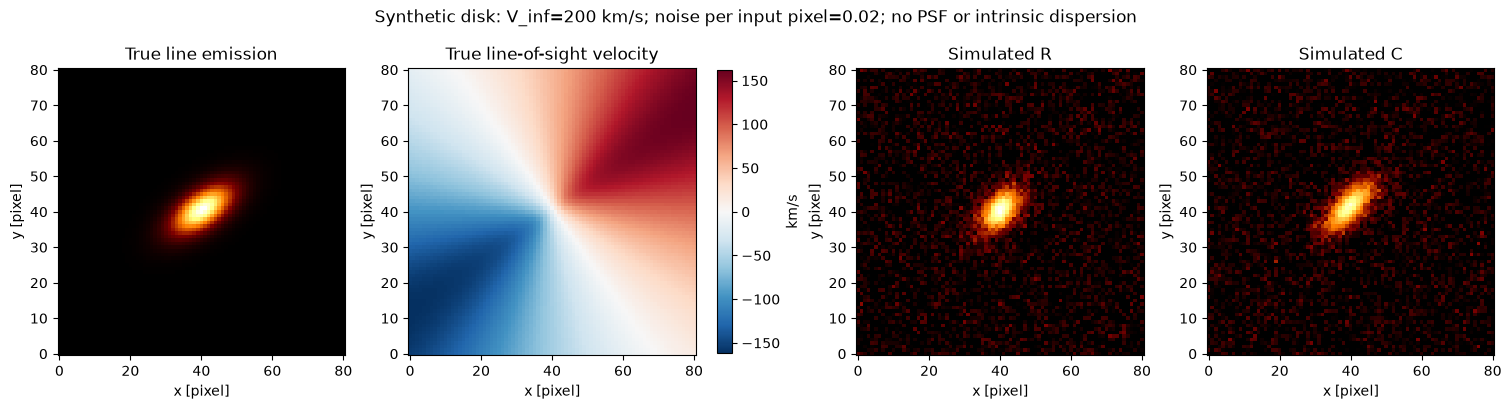

In [2]:
mock = sim.make_mock(
    SAVE_ROOT / EXPERIMENT,
    velocity=200.0, turnover=5.0, inclination=60.0, pa=35.0,
    center=(40.3, 40.7), effective_radius=6.0, peak=1.0,
    noise_sigma=0.02, seed=42, overwrite=OVERRIDE,
)
experiment = forward.ForwardExperiment(mock, device=DEVICE)
fig = inputs.show_inputs(mock)
display(fig)
plt.close(fig)

## 2. Check the direct prediction

The true emission map and all parameters except velocity are known here. The noiseless curve should reach zero residual at the injected velocity. Each plot subtracts its own minimum. This tests numerical consistency using the same forward model for generation and recovery; it does not yet establish real-data accuracy.

Direct R+C velocity check:   0%|          | 0/41 [00:00<?, ?it/s]

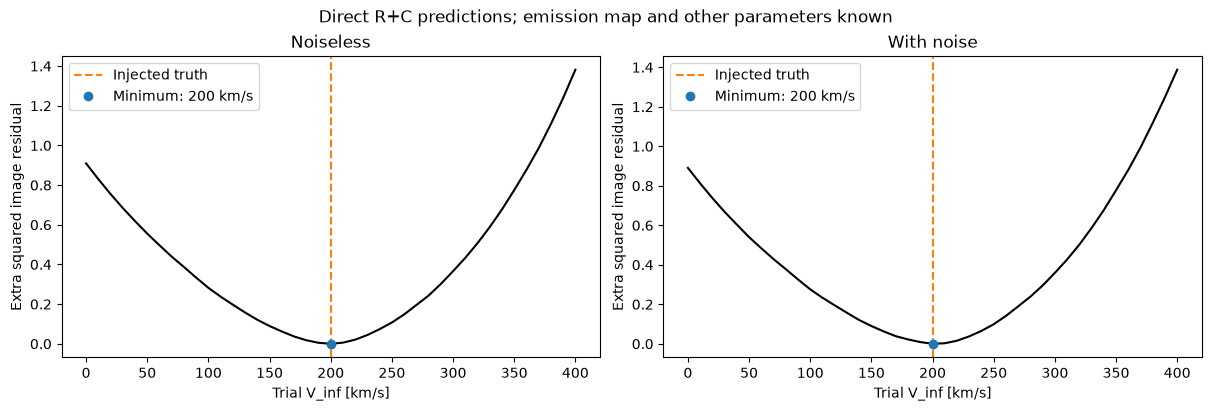

In [3]:
scan, fig = review.scan_velocity(experiment, np.arange(0.0, 401.0, 10.0))
display(fig)
plt.close(fig)

## 3. Fit from different starting velocities

Fit **velocity, turnover radius, orientation, and R x/y registration**. The true emission map, center, and inclination remain fixed. The starts deliberately use a different turnover radius and orientation. The table shows the actual final parameters; `finished` refers only to the optimizer.

In [4]:
fits = {}
for start in (75.0, 350.0, 800.0):
    fits[start] = experiment.fit(
        start, start_turnover=3.0, start_pa=20.0, start_offset=(0.2, -0.2),
        noisy=experiment.sigma > 0, max_evaluations=2000,
    )
    print(f"Start {start:g}: fitted V_inf={fits[start]['theta'][0]:.2f} km/s; {fits[start]['message']}")
display(review.compare_starts(experiment, list(fits.values())))

Start 75: fitted V_inf=197.35 km/s; Optimization terminated successfully.
Start 350: fitted V_inf=198.45 km/s; Optimization terminated successfully.
Start 800: fitted V_inf=209.53 km/s; Optimization terminated successfully.


,start_V_inf,fitted_V_inf,true_V_inf,fitted_R_t,fitted_PA_deg,R_dx,R_dy,chi2,finished
0,75.0,197.345166,200.0,4.874818,34.329507,0.001947,0.001576,13068.815242,True
1,350.0,198.451681,200.0,4.924106,34.238311,0.001408,-0.000549,13068.750087,True
2,800.0,209.525486,200.0,5.218493,34.511329,-0.004141,-0.002353,13068.048652,True


## 4. MCMC with the emission map known

These errors are **conditional on knowing the emission map, center, and inclination**. Morphology uncertainty is not included. This is a numerical recovery test, not the posterior we would report for a real source.

Emcee uses the batched PyTorch prediction on the selected device. Progress bars and retained-sample checkpoints are enabled. These short defaults let you inspect recovery; more samples and repeated noise realizations are needed to assess convergence and coverage.

In [5]:
MCMC_START = 350.0
RESULT_DIR = None
if experiment.sigma > 0:
    RESULT_DIR = review.sample(
        experiment, fits[MCMC_START],
        warmup=100, draws=500, walkers=32, seed=42,
        progress="notebook", overwrite=OVERRIDE,
    )
else:
    print("Noiseless test: inspect fitted values; no measurement-noise error bars.")

  0%|          | 0/100 [00:00<?, ?it/s]

  0%|          | 0/500 [00:00<?, ?it/s]

Known-map conditional posterior saved in: /home/aakavan/kinematics/grism-kinematics/results/simulations/disk_200_forward/direct_known_map


## 5. Compare MCMC with the truth

Orange lines mark the injected values. Residual panels show **input − prediction** in each original grism image, divided by its known noise. Every retained walker enters the summaries. Outputs are in `<experiment>/direct_known_map/`.

To reopen results, load `mock = sim.load_mock(SAVE_ROOT / EXPERIMENT)`, recreate `experiment = forward.ForwardExperiment(mock, device=DEVICE)`, set `RESULT_DIR = mock.directory / "direct_known_map"`, and run this cell.

Intervals condition on the true emission map, center and inclination.
Status: finished Acceptance: 0.5441875
Retained steps / estimated autocorrelation time: [15.274949468363296, 15.899635748836287, 16.35350113366919, 18.104861265235296, 17.160618670132358]


,truth,median,minus_16th,plus_84th
V_inf [km/s],200.0,205.056000,8.827632,9.963114
R_t [pixel],5.0,5.099544,0.279331,0.319451
PA [deg],35.0,34.356413,0.924631,1.004384
R_dx [pixel],0.0,-0.000886,0.010253,0.011280
R_dy [pixel],0.0,-0.001684,0.018418,0.020333


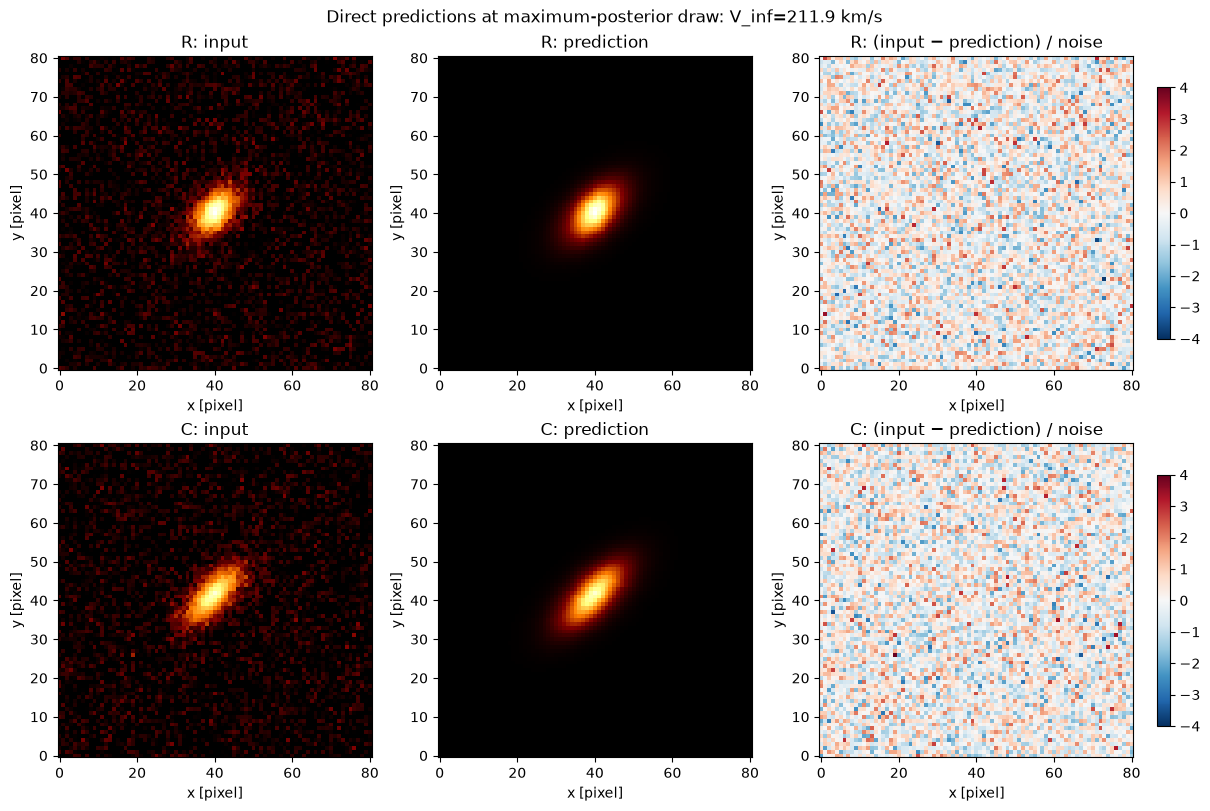

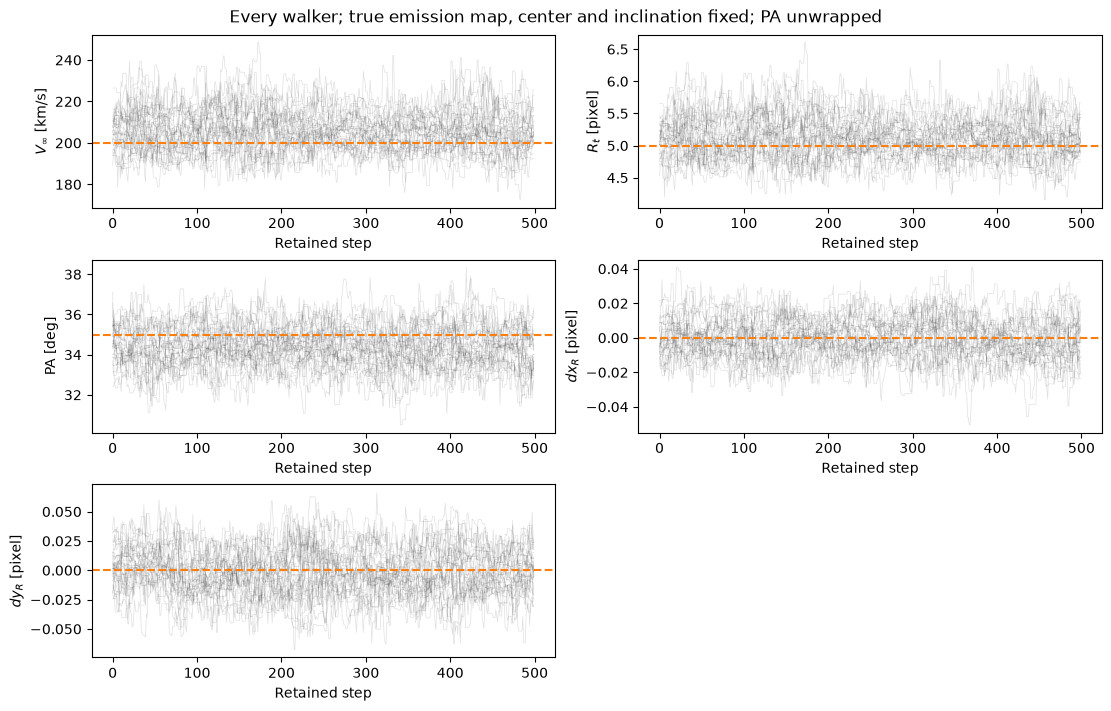

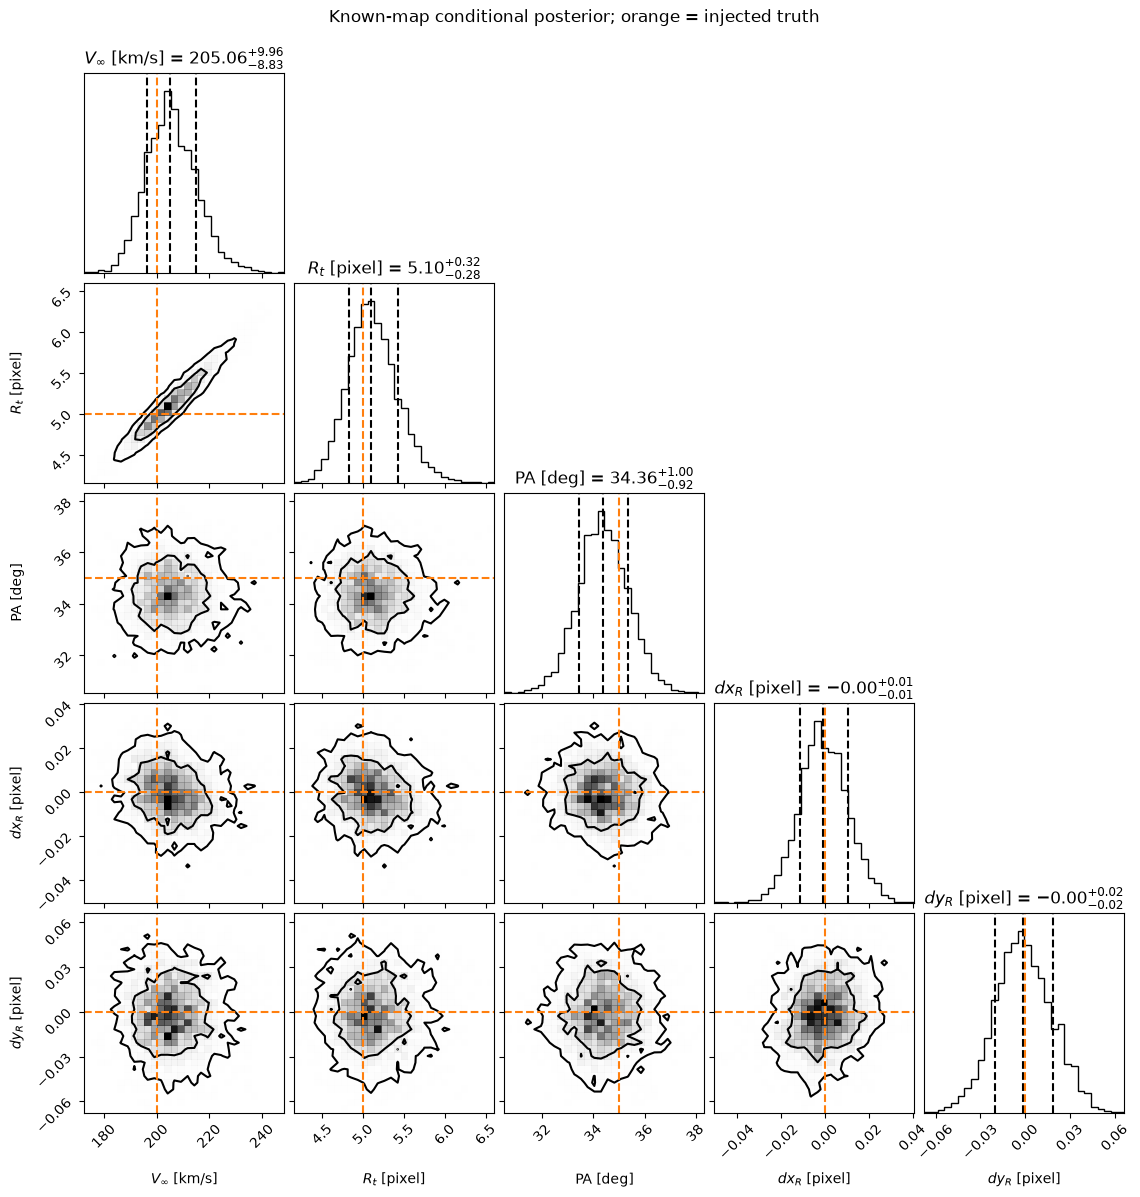

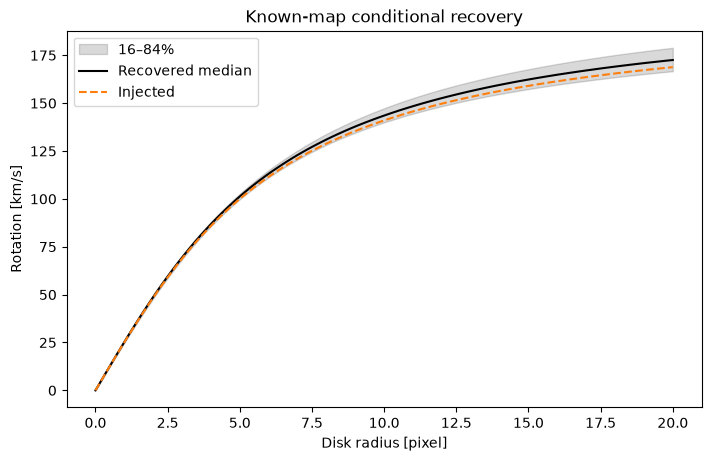

In [6]:
if RESULT_DIR is not None:
    views = review.show_results(experiment, RESULT_DIR)
    display(views["summary"])
    for name in ("residuals", "traces", "corner", "rotation_curve"):
        display(views[name])
        plt.close(views[name])

## 6. Let R+C determine the emission map

Now every source pixel has an independent **nonnegative** brightness fitted jointly to R and C. There is **no Sérsic shape or smoothing prior**, and the injected emission map is not supplied to this solver.

First scan velocity while holding the other kinematic parameters at truth. Then fit all five parameters from a displaced start. Center and inclination remain fixed. This profiles over the map: it gives best fits, **not marginalized MCMC error bars**. The map solve uses CPU sparse linear algebra even when the coordinate model uses CUDA. Results save separately in `<experiment>/direct_free_map/`.

Free map: Noiseless:   0%|          | 0/17 [00:00<?, ?it/s]

Free map: With noise:   0%|          | 0/17 [00:00<?, ?it/s]

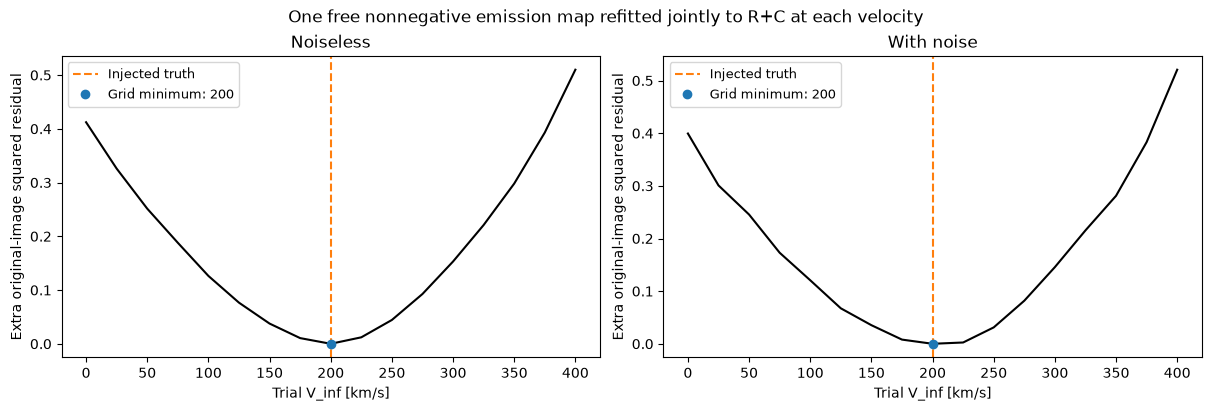

Free-map fit evaluations:   0%|          | 0/150 [00:00<?, ?it/s]

Free-map profile fit; no marginalized MCMC errors are reported.
Outer optimizer: True CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*EPSMCH
Inner nonnegative solve: True optimality: 1.4850279098240458e-07
Outer gradient criterion met: False (a small change in the score can stop the optimizer before this criterion is met)


,truth,fitted
V_inf [km/s],200.0,215.318164
R_t [pixel],5.0,5.738720
PA [deg],35.0,25.214392
R_dx [pixel],0.0,-0.069509
R_dy [pixel],0.0,-0.256323


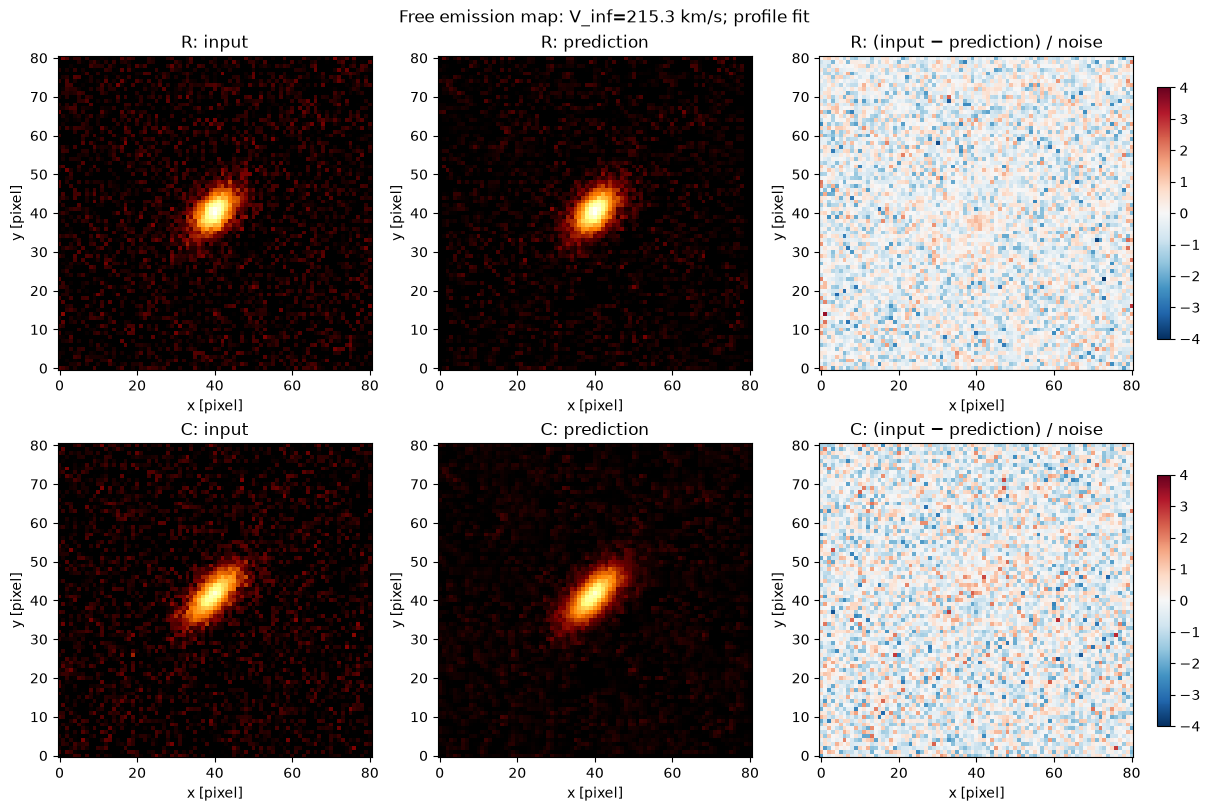

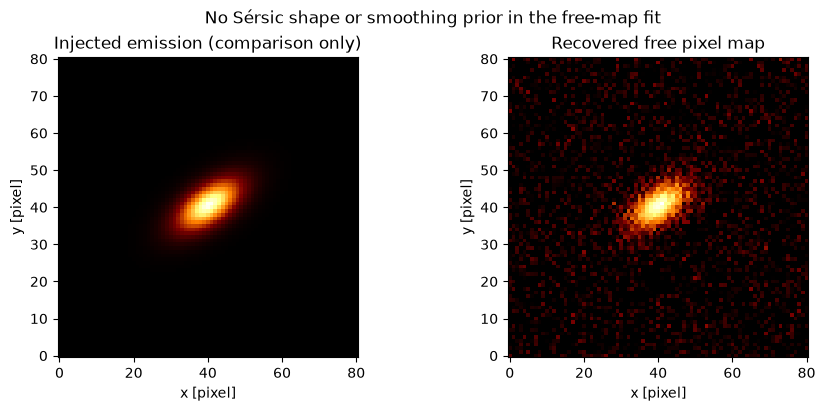

In [7]:
free_scan, fig = flexible.scan_velocity(experiment, np.arange(0.0, 401.0, 25.0))
display(fig)
plt.close(fig)

free_fit = flexible.fit(
    experiment, start_velocity=350.0, start_turnover=3.0, start_pa=20.0,
    start_offset=(0.2, -0.2), noisy=experiment.sigma > 0, max_evaluations=150,
)
free_views = review.show_free_result(experiment, free_fit)
display(free_views["summary"])
for name in ("residuals", "emission"):
    display(free_views[name])
    plt.close(free_views[name])